[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# A Station Atlas


## What you will be able to do

This notebook takes a CSV register of station coordinates through every step of the guide. You end
with a map and a GeoPackage of two layers that give each station its district, its distance to the
coast and its nearest named station.

## The idea

### The problem

The weather service exports its register of 300 stations every month as a CSV file of ids,
latitudes, longitudes, elevations, owners and installation years. The forecast office wants an atlas
made from it: every station with its district, its distance from the coast and the named station
nearest to it, a table of the districts with their stations counted and averaged, a map, and a file
that a colleague can open in a desktop mapping program such as QGIS.

Each of those steps has a notebook of its own earlier in this guide. Done together they raise
questions that no single notebook had to answer: which CRS to work in from the start, what the coast
is when Norway's outline also runs along its borders with Sweden, Finland and Russia, and how to
check each step before the next one depends on it.

### A formal definition

> A **GeoPackage** is a single file, built on SQLite, that holds one or more named **layers**. Each
> layer is a table with a geometry column, its CRS and its other columns, so one file can carry the
> stations as points and the districts as polygons, each with the attributes the atlas gave it.

### Why it works that way

The register arrives as text, so its geometry has to be made, longitude first, and its CRS stated.
Every measurement in the atlas is a distance or an area, so the stations are converted once to UTM
zone 33N, which measures in meters, and every other layer is converted to match before it is used.
After that, a spatial join, a distance and a sum all work in meters.

Norway's outline is the edge of the land, and only part of that edge is coast. The rest runs along
land borders, and a station 10 km from Sweden would be measured as 10 km from the sea. The coast is
the outline's boundary with the land borders taken out, a difference between two shapes.

A summary by district comes from the stations, so that a mean over a district is a mean over its
stations, and it is merged into the districts' table, so that it stays a GeoDataFrame that can be
mapped and written. Each step prints a count that the next one can be checked against.

### Where this shows up

Any table of places can go through the same steps in this order: read, give it geometry, project,
join, measure, summarize, map, write. The **Spatial Joins**, **Nearest Neighbors** and **Making Maps** notebooks
cover the steps one at a time, and the **Reading and Writing Files** notebook covers GeoPackage layers.

### What this notebook covers

- the register read from a CSV file and given geometry in UTM zone 33N
- each station's district, distance from the coast and nearest named station
- a summary of the districts, merged into their table
- two maps
- a GeoPackage with two layers, read back
- three mistakes that come from putting the steps together

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
import geopandas as gpd
from shapely.geometry import LineString, Point, box

land = box(0, 0, 10, 10)
border = LineString([(10, 0), (10, 10)])
coast = land.boundary.difference(border.buffer(0.01))
sites = gpd.GeoSeries([Point(2, 5), Point(9, 5)])
print(sites.distance(land.boundary).round(2).tolist())
print(sites.distance(coast).round(2).tolist())
```

```
[2.0, 1.0]
[2.0, 5.0]
```

The square of land has a land border on its right side. The second site is 1 from the edge of the
land, but that edge is the border, and it is 5 from the nearest stretch of coast.

## Setup

Two libraries for the tables, GeoPandas and Shapely for the geometry, pyogrio for the GeoPackage's
layers, Matplotlib for the maps, and two tools for the scratch folder.

- `Path` finds the guide's copy of the country outlines, and names the scratch folder and its files
- `shutil` removes the scratch folder at the end of the notebook
- `numpy` and `pandas` build the made-up register and read it back from a CSV file
- `geopandas` does every spatial step, and the cell prints its version
- `shapely` is the geometry library under GeoPandas, used here to build the districts
- `pyogrio` lists the layers of a GeoPackage, and the cell prints its version
- `matplotlib.pyplot` draws the maps

`countries` holds the outlines of Denmark, Finland, Norway, Russia and Sweden. Made with Natural Earth.
The outlines come from Natural Earth's 1:50m map of the world's countries, which is in the public
domain.

`network` is the register of 300 weather stations as a plain table, `named` is the five named stations
in latitude and longitude, and `districts` is the eight forecast districts in UTM zone 33N. The
stations and the districts are made up. The stations are drawn at random over mainland Norway from a
fixed seed, and the districts are drawn around eight chosen centers and cut to Norway's outline. The
cell makes a folder, `scratch`, for the files the notebook writes.

In [1]:
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import pyogrio
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

network = station_network()
districts = forecast_districts()
scratch = Path("scratch")
scratch.mkdir(exist_ok=True)
print("geopandas", gpd.__version__, "| pyogrio", pyogrio.__version__, "|", len(countries), "countries,",
      len(network), "made-up stations,", len(districts), "made-up districts")

geopandas 1.2.0 | pyogrio 0.13.0 | 5 countries, 300 made-up stations, 8 made-up districts


## Worked examples

### The register as the service exports it

The register is written to a CSV file, as the service would send it, and read back. What comes back
is text turned into numbers by pandas, with no geometry.

In [2]:
network.to_csv(scratch / "register.csv", index=False)
register = pd.read_csv(scratch / "register.csv")
print(type(register).__name__, register.shape)
register.head(3)

DataFrame (300, 6)


,station,latitude,longitude,elevation_m,owner,installed
0,NS001,61.1793,10.6233,191,met,2019
1,NS002,64.8072,13.5681,325,met,2003
2,NS003,70.7203,24.4802,361,met,1956


### Geometry in one CRS for the whole atlas

The points are made from the longitude and latitude, in EPSG:4326, and converted at once to UTM zone
33N. Every later step works in meters.

In [3]:
atlas = gpd.GeoDataFrame(
    register, geometry=gpd.points_from_xy(register["longitude"], register["latitude"]), crs=4326
).to_crs(25833)
countries_m = countries.to_crs(25833)
named_m = named.to_crs(25833)
print("atlas CRS:", atlas.crs.name, "| districts CRS:", districts.crs.name)
print("stations inside Norway's outline:",
      atlas.within(countries_m.loc[countries_m["ADMIN"] == "Norway", "geometry"].iloc[0]).sum())

atlas CRS: ETRS89 / UTM zone 33N | districts CRS: ETRS89 / UTM zone 33N
stations inside Norway's outline: 300


Both layers are in ETRS89 / UTM zone 33N, and all 300 stations fall inside Norway's outline, so no
longitude was swapped with its latitude and none came back missing from the CSV file.

### Each station's district

In [4]:
atlas = gpd.sjoin(atlas, districts, how="left").drop(columns="index_right")
print("stations without a district:", atlas["district"].isna().sum())
atlas.groupby("district").size().reindex(districts["district"], fill_value=0)

stations without a district: 0


district
South        32
East         56
West         43
Mid          69
North        27
Far North    25
Northeast    48
Svalbard      0
dtype: int64

Every station has a district. Dropping `index_right` immediately after the join lets the next join
run, since `sjoin_nearest` raises `ValueError` when the column already exists, as the **Spatial Joins**
notebook showed. Svalbard has no stations, and the
`reindex` keeps it in the count as 0.

### The coast

Norway's outline runs along the sea and along three land borders. The land borders are where the
outline touches the neighboring countries, so the coast is the outline's boundary minus a band
reaching 1 km out from the neighbors, a margin in case two outlines do not meet exactly.

In [5]:
norway = countries_m.loc[countries_m["ADMIN"] == "Norway", "geometry"].iloc[0]
neighbors = countries_m.loc[countries_m["ADMIN"] != "Norway", "geometry"].union_all()
edge = norway.boundary
coast = edge.difference(neighbors.buffer(1_000))
print("Norway's edge:", round(edge.length / 1000), "km")
print("along land borders:", round(edge.intersection(neighbors.buffer(1_000)).length / 1000), "km")
print("coast:", round(coast.length / 1000), "km,", coast.geom_type)

Norway's edge: 14937 km
along land borders: 2344 km
coast: 12593 km, MultiLineString


Of the 14,937 km of edge in the 1:50m outline, 2,344 km run along land borders, which leaves 12,593 km
of coast, Svalbard's included. The length depends on the outline's scale, since a finer outline
follows more fjords and skerries, so this figure belongs to the 1:50m outline.

### Distance from the coast

In [6]:
atlas["coast_km"] = (atlas.distance(coast) / 1000).round(1)
print(atlas["coast_km"].describe().round(1))
print("within 10 km of the coast:", (atlas["coast_km"] < 10).sum())

count    300.0
mean      51.1
std       49.5
min        0.3
25%       12.0
50%       33.4
75%       74.4
max      217.9
Name: coast_km, dtype: float64
within 10 km of the coast: 60


Half the stations stand within 33.4 km of the coast, and the farthest is 217.9 km inland. 60 stations
are within 10 km of the sea.

### The nearest named station

`sjoin_nearest` gives each station the named station closest to it, and `distance_col` records the
distance in meters.

In [7]:
atlas = gpd.sjoin_nearest(atlas, named_m[["name", "geometry"]], how="left", distance_col="named_m")
atlas = atlas.drop(columns="index_right")
atlas["named_km"] = (atlas.pop("named_m") / 1000).round(1)
print("rows:", len(atlas))
atlas.groupby("name").size().reindex(named["name"], fill_value=0)

rows: 300


name
Bergen       67
Oslo        129
Svalbard      0
Tromso       74
Kirkenes     30
dtype: int64

Each of the 300 stations kept one row, so no station was tied between two named stations. Oslo is the
nearest named station to 129 stations, and Svalbard to none, since every station is on the mainland.

### A summary of the districts

The summary is computed from the stations, then merged into the districts' table, which keeps it a
GeoDataFrame with the districts' shapes.

In [8]:
summary = atlas.groupby("district").agg(
    stations=("station", "size"),
    elevation_m=("elevation_m", "mean"),
    coast_km=("coast_km", "mean"),
    named_km=("named_km", "mean"),
).round(1)

district_atlas = districts.merge(summary, left_on="district", right_index=True, how="left")
district_atlas["stations"] = district_atlas["stations"].fillna(0).astype(int)
district_atlas["area_km2"] = (district_atlas.area / 1e6).round(0).astype(int)
district_atlas["per_10k_km2"] = (district_atlas["stations"] / district_atlas["area_km2"] * 10_000).round(1)
print(type(district_atlas).__name__)
district_atlas.drop(columns="geometry")

GeoDataFrame


,district,stations,elevation_m,coast_km,named_km,area_km2,per_10k_km2
0,South,32,332.8,37.6,159.5,36056,8.9
1,East,56,393.8,118.1,132.0,62504,9.0
2,West,43,349.5,26.7,140.5,53904,8.0
3,Mid,69,354.7,51.2,399.8,61575,11.2
4,North,27,375.1,18.2,390.0,30984,8.7
5,Far North,25,340.5,19.2,106.1,31283,8.0
6,Northeast,48,376.0,38.8,153.3,48523,9.9
7,Svalbard,0,NaN,NaN,NaN,62068,0.0


The districts' table is on the left of the merge, so the result keeps its geometry and is still a
GeoDataFrame. Svalbard's means are `NaN`, since it has no stations to average. The East district's
stations stand 118.1 km from the coast on average, the farthest of any district, and the Mid district's
are farthest from a named station, 399.8 km.

### The maps

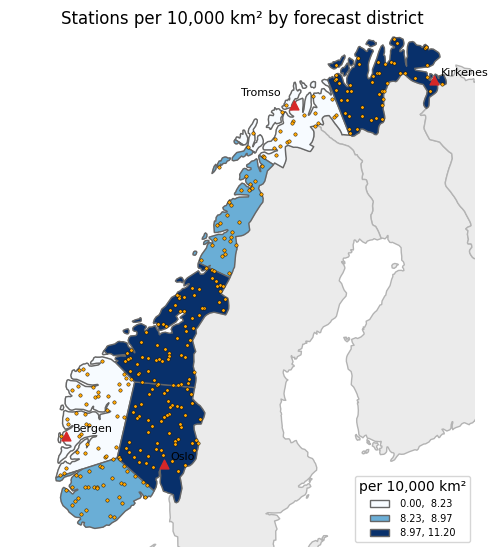

In [9]:
fig, ax = plt.subplots(figsize=(6, 7))
countries_m.plot(ax=ax, color="0.92", edgecolor="0.7")
district_atlas.plot(ax=ax, column="per_10k_km2", scheme="Quantiles", k=3, cmap="Blues", edgecolor="0.4",
                    legend=True, legend_kwds={"loc": "lower right", "fontsize": 7,
                                              "title": "per 10,000 km²"})
atlas.plot(ax=ax, color="orange", edgecolor="black", linewidth=0.3, markersize=6)
named_m.plot(ax=ax, color="tab:red", marker="^", markersize=40)
offsets = {"Tromso": (-38, 6)}
for name, point in zip(named_m["name"], named_m.geometry):
    ax.annotate(name, (point.x, point.y), xytext=offsets.get(name, (5, 3)), textcoords="offset points",
                fontsize=8)
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Stations per 10,000 km² by forecast district")
plt.show()

The darkest districts, East, Mid and Northeast, have the most stations for their area. Svalbard, with
none, is off the top of the map.

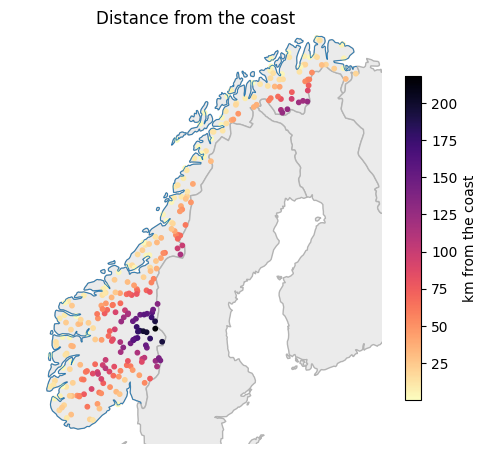

In [10]:
fig, ax = plt.subplots(figsize=(6, 7))
countries_m.plot(ax=ax, color="0.92", edgecolor="0.7")
gpd.GeoSeries([coast], crs=25833).plot(ax=ax, color="tab:blue", linewidth=0.6)
atlas.plot(ax=ax, column="coast_km", cmap="magma_r", markersize=10, legend=True,
           legend_kwds={"label": "km from the coast", "shrink": 0.6})
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Distance from the coast")
plt.show()

The blue line is `coast`, as the section on the coast built it, and it stops where Norway meets Sweden,
Finland and Russia. The darkest points, far inland, lie in the East district, where Norway is widest.

### A GeoPackage with two layers

`to_file` writes a layer, and a second call with another `layer` adds it to the same file. Each layer
keeps its own geometry type and CRS.

In [11]:
atlas_gpkg = scratch / "atlas.gpkg"
district_atlas.to_file(atlas_gpkg, layer="districts")
atlas.to_file(atlas_gpkg, layer="stations")
pyogrio.list_layers(atlas_gpkg)

array([['districts', 'MultiPolygon'],
       ['stations', 'Point']], dtype=object)

In [12]:
stations_back = gpd.read_file(atlas_gpkg, layer="stations")
print("rows:", len(stations_back), "| CRS:", stations_back.crs.to_epsg())
print(list(stations_back.columns))

rows: 300 | CRS: 25833
['station', 'latitude', 'longitude', 'elevation_m', 'owner', 'installed', 'district', 'coast_km', 'name', 'named_km', 'geometry']


The stations come back with their 300 rows, their CRS, EPSG:25833, and every column the atlas added,
`district`, `coast_km`, `name` and `named_km` among them. A colleague opening the file in a mapping
program sees the same two layers.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/13-a-station-atlas-solutions.ipynb).

**1.** Print the five stations closest to the coast, with their districts and distances.

In [13]:
# your code here

**2.** For each owner, print how many of their stations stand within 10 km of the coast.

In [14]:
# your code here

**3.** Find the station farthest from any named station, and print its id, its district, the named station nearest to it and the distance.

In [15]:
# your code here

**4.** Add to `district_atlas` the share of each district's stations that stand within 10 km of the coast, and draw it as a map with three quantile classes.

In [16]:
# your code here

**5.** Write the named stations, in UTM zone 33N, to a GeoPackage of their own in `scratch` alongside a layer of the districts, and print the file's layers.

In [17]:
# your code here

## Common errors

### `AttributeError: 'DataFrame' object has no attribute 'to_crs'`

In [18]:
pd.read_csv(scratch / "register.csv").to_crs(25833)

AttributeError: 'DataFrame' object has no attribute 'to_crs'

`read_csv` returns a plain DataFrame, and a CSV file has no geometry and no CRS for it to keep. Make
the points with `points_from_xy`, state `crs=4326`, and only then convert, as the worked examples do.

### No error, and the Swedish border measured as coast

In [19]:
check = atlas[["station", "district", "coast_km"]].copy()
check["edge_km"] = (atlas.distance(norway.boundary) / 1000).round(1)
print("stations nearer a land border than the coast:", (check["edge_km"] < check["coast_km"]).sum())
check.loc[[(check["coast_km"] - check["edge_km"]).idxmax()]]

stations nearer a land border than the coast: 92


,station,district,coast_km,edge_km
238,NS239,East,217.9,10.5


Measured to Norway's whole edge, 92 stations would be given the distance to a land border instead of
the coast. Station NS239, in the East district, would be 10.5 km from the sea, where it stands 217.9 km
inland and 10.5 km from Sweden. Nothing fails, because the outline's boundary is a line like any other.
Take the land borders out of the boundary first, as the worked examples did with `difference`.

### No error, and a layer that lost six of its rows

In [20]:
district_atlas.head(2).to_file(atlas_gpkg, layer="districts")
print("districts layer:", len(gpd.read_file(atlas_gpkg, layer="districts")), "rows")
print(pyogrio.list_layers(atlas_gpkg)[:, 0].tolist())

districts layer: 2 rows
['stations', 'districts']


Writing a layer that already exists replaces it, so the districts layer now holds the two rows just
written, and the stations layer is untouched. The default is `mode="w"`, which writes a layer from
scratch, and `mode="a"` adds rows to the end of a layer instead, which the next cell shows. Write each
layer once, from the complete table, and use `mode="a"` only to add rows that are new.

In [21]:
district_atlas.head(2).to_file(atlas_gpkg, layer="districts", mode="a")
print("after appending two rows:", len(gpd.read_file(atlas_gpkg, layer="districts")), "rows")
district_atlas.to_file(atlas_gpkg, layer="districts")
print("after writing the full table:", len(gpd.read_file(atlas_gpkg, layer="districts")), "rows")
shutil.rmtree(scratch)
print("scratch folder left:", scratch.exists())

after appending two rows: 4 rows
after writing the full table: 8 rows
scratch folder left: False


Appending the same two rows makes four, and writing the full table again restores the layer to its
eight rows. The last line removes the scratch
folder and everything the notebook wrote into it.

## Recap

- You can take a CSV register of coordinates to a GeoDataFrame in a projected CRS, and check that its
  points fall where they should.
- You can build a coastline from an outline by removing its land borders, and measure distances to it.
- You can give every point its district and its nearest named station, and summarize the points by
  district in a table that stays a GeoDataFrame.
- You can map the results and write them to a GeoPackage of several layers without replacing a layer
  by accident.

## What is next

The **Shapely, Deep Dive** guide works with the geometries on their own, outside a table, from
intersections and buffers to the invalid shapes that stop a calculation, and the library's front page
lists every guide.

---

&#8592; **Previous:** [Making Maps](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/12-making-maps.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)
